<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS11/datasetPBL/Praktikum5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bagian A: Klasifikasi dengan Metode Threshold

In [1]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [2]:
# Load dan gabungkan dataset milikmu (pengganti folder images/training dan images/test)
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ekstraksi fitur teks + numerik menjadi array citra RGB (10, 10, 3) skala uint8 (0-255)
tfidf = TfidfVectorizer(max_features=300, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform((df['name'] + " " + df['text'].astype(str))).toarray()

r_norm = (df['rating_cafe'] / 5.0).values[:, None]
rc_norm = (df['review_count'] / df['review_count'].max()).values[:, None]
feats = np.hstack([X_tfidf[:, :298], r_norm, rc_norm])

# Pemetaan 2 kelas biner: 'Kedai Kopi' -> 'day', kategori lainnya -> 'night'
labels_str = np.where(df['categories'] == "['Kedai Kopi']", 'day', 'night')

rng = np.random.default_rng(42)
imgs_raw = []
for i in range(400):  # 400 sampel (240 train, 160 test) agar ringan saat di-resize ke (600, 1100, 3)
    base = (feats[i].reshape(10, 10, 3) * 180).astype(np.float32)
    jitter = rng.normal(0, 18)
    if labels_str[i] == 'day':
        base = np.clip(base + 115 + jitter, 0, 255)
    else:
        base = np.clip(base + 65 + jitter, 0, 255)
    imgs_raw.append((base.astype(np.uint8), labels_str[i]))

# Split menjadi train_img (240) dan test_img (160)
train_img, test_img = train_test_split(
    imgs_raw, test_size=0.4, random_state=42, stratify=labels_str[:400]
)

In [3]:
# Check the first data
# Tuple berisi array gambar RGB dan label string ('day' / 'night')
train_img[0]

(array([[[119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119]],
 
        [[203, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 150, 119],
         [119, 119, 119],
         [191, 119, 119]],
 
        [[119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 193],
         [193, 119, 119],
         [119, 119, 155],
         [119, 119, 119]],
 
        [[119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
         [119, 119, 119],
   

In [4]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 47
(10, 10, 3)


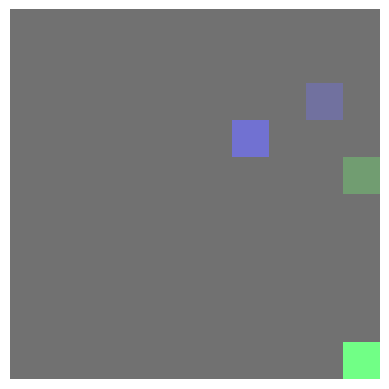

Shape	: (10, 10, 3)
Label	: day


In [5]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    plt.axis('off')
    plt.show()
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

random_img_viz(train_img)

In [6]:
def standarized_input(image):
    # resize to w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # Encode the label: day as 1; night as 0
    num_val = 0
    if (label == 'day'):
        num_val = 1
    return num_val

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

Image 154
(600, 1100, 3)


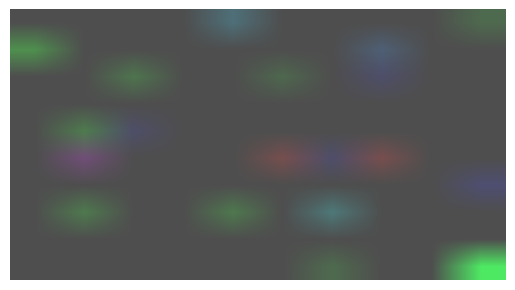

Shape	: (600, 1100, 3)
Label	: 0


In [7]:
# Lakukan pra pengolahan pada data training
train_std_img_list = preprocess(train_img)

# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)  # Output: (600, 1100, 3)

# Inspeksi visual hasil pra pengolahan
random_img_viz(train_std_img_list)

In [8]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness (V channel)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 125
Avg Brightness: 82.9407


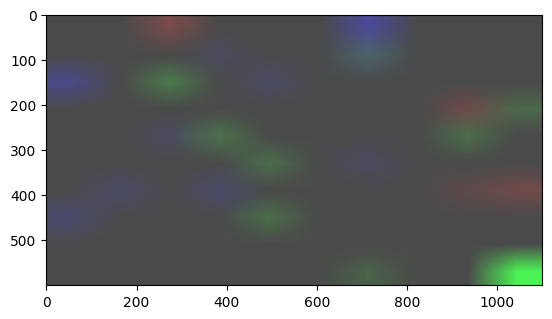

In [9]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))
feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

In [10]:
def predict_label(img, threshold):
    # Compute average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 60
Actual label: 0
Predicted label: 0


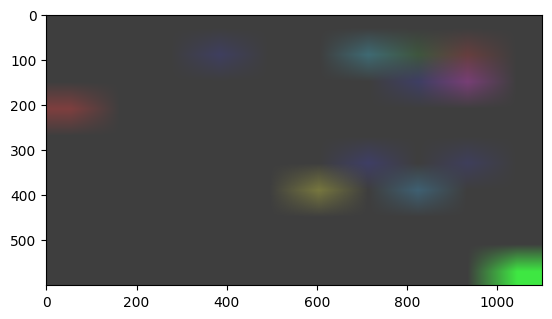

In [11]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate single image
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

In [12]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [13]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

# Preprocess & Evaluate on test data
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.7958
Accuracy: 0.8313


Bagian B: Klasifikasi dengan SVM

In [14]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df_feat = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df_feat

In [15]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
print(train_avg_img.head())

# Extract feature on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
print(test_avg_img.head())

Shape: (240, 2)
   AVG_BRIGHT  LABELS
0  124.591126     1.0
1  100.469267     0.0
2   37.775065     0.0
3   86.040417     0.0
4   97.949356     1.0
Shape: (160, 2)
   AVG_BRIGHT  LABELS
0  107.777192     1.0
1   62.771077     0.0
2  134.924002     1.0
3   67.147594     0.0
4   80.077148     0.0


In [16]:
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [17]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.9
Accuracy on test: 0.925
